# Opgave 2: Klassifikation af DermaMNIST med en enkel CNN

**Formål:** Undersøge, hvordan en lille CNN kan skelne mellem syv typer
hudlæsioner i DermaMNIST, og hvilke klasser modellen har svært ved.

Vi træner fra bunden på 28 × 28 RGB-billeder. To learning rates sammenlignes
på valideringssættet. Derefter evalueres den valgte model én gang på testsættet.
En majoritetsbaseline viser, hvorfor accuracy alene er utilstrækkelig.

Kør cellerne fra toppen. `Forklaring.txt` gennemgår både kode og begrundelser
grundigt. `Rapport.md` beskriver det gennemførte forsøg i opgavens rapportstruktur.

**Databegrænsning:** De officielle splits har dokumenteret overlap af læsioner
[3]. Vi bevarer benchmark-splittene, men kalder dem ikke patientuafhængige.
Resultaterne beskriver dette benchmark og kan ikke sidestilles med klinisk validering.


## 1. Opsætning

Vælg en Python-kernel med pakkerne fra `requirements.txt`.
I Colab kan installationslinjen nedenfor aktiveres. Data og resultater gemmes
i `Assignment_2`, også hvis notebooken startes fra repositoryets rodmappe.
CUDA bruges, hvis det er tilgængeligt; ellers CPU. CPU er tilstrækkelig her.


In [1]:
# Kun ved manglende pakker i Colab: fjern # og kør linjen.
# %pip install medmnist==3.0.2 scikit-learn matplotlib

from copy import deepcopy
from pathlib import Path
import csv
import json
import platform
import random
import time

import matplotlib.pyplot as plt
import medmnist
import numpy as np
import sklearn
import torch
import torchvision
from medmnist import DermaMNIST, INFO
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, roc_auc_score, roc_curve,
)
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 30
PATIENCE = 8
LEARNING_RATES = [1e-3, 3e-4]
WEIGHT_DECAY = 1e-4
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, torch.get_num_threads()))

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
BASE_DIR = Path.cwd()
if (BASE_DIR / 'Assignment_2').is_dir():
    BASE_DIR = BASE_DIR / 'Assignment_2'
DATA_DIR = BASE_DIR / 'data'
RESULTS_DIR = BASE_DIR / 'results'
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

info = INFO['dermamnist']
CLASS_NAMES = [info['label'][str(i)] for i in range(len(info['label']))]
SHORT_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
NUM_CLASSES = len(CLASS_NAMES)
VERSIONS = {name: str(module.__version__) for name, module in [
    ('torch', torch), ('torchvision', torchvision), ('medmnist', medmnist),
    ('numpy', np), ('scikit-learn', sklearn), ('matplotlib', __import__('matplotlib')),
]}
print('Device:', DEVICE, '| Python:', platform.python_version())
print('Pakkeversioner:', VERSIONS)
print('Resultatmappe:', RESULTS_DIR)

def save_figure(name):
    plt.savefig(RESULTS_DIR / name, dpi=160, bbox_inches='tight')
    plt.show()

def write_csv(name, rows):
    with (RESULTS_DIR / name).open('w', newline='', encoding='utf-8') as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


Device: cpu | Python: 3.11.16
Pakkeversioner: {'torch': '2.14.0', 'torchvision': '0.29.0', 'medmnist': '3.0.2', 'numpy': '2.4.6', 'scikit-learn': '1.9.0', 'matplotlib': '3.11.1'}
Resultatmappe: /Users/frederikthygesen/Desktop/5 Semester/Deep Learning/Assignment 1/Deeplearning/Assignment_2/results


## 2. Data og indledende analyse

DermaMNIST bygger på HAM10000 [1, 2]. Der er 10.015 billeder fordelt på
7.007 træningsbilleder, 1.003 valideringsbilleder og 2.005 testbilleder.
Hvert billede har én label fra 0 til 6; det er multiclass-klassifikation.

Vi undersøger træningsbillederne før modellering. Testdata indlæses først
efter modelvalget. MedMNIST downloader én NPZ-fil, som indeholder alle splits;
det betyder ikke, at testdata indgår i træningen.


In [2]:
train_data = DermaMNIST(root=str(DATA_DIR), split='train', size=28, download=True)
val_data = DermaMNIST(root=str(DATA_DIR), split='val', size=28, download=False)
y_train = train_data.labels.reshape(-1)
train_counts = np.bincount(y_train, minlength=NUM_CLASSES)
assert train_data.imgs.shape == (7007, 28, 28, 3)
assert len(val_data) == 1003
assert np.all(train_counts > 0)

print('Train:', train_data.imgs.shape, '| Validation:', val_data.imgs.shape)
print('Pixels:', train_data.imgs.dtype, train_data.imgs.min(), train_data.imgs.max())
for i, name in enumerate(CLASS_NAMES):
    print(f'{i}: {SHORT_NAMES[i]:5s} | {train_counts[i]:4d} billeder | {name}')
majority_class = int(train_counts.argmax())
print(f'Majoritetsklasse: {SHORT_NAMES[majority_class]} '
      f'({train_counts.max() / len(y_train):.1%} af træningsdata)')


Train: (7007, 28, 28, 3) | Validation: (1003, 28, 28, 3)
Pixels: uint8 0 255
0: akiec |  228 billeder | actinic keratoses and intraepithelial carcinoma
1: bcc   |  359 billeder | basal cell carcinoma
2: bkl   |  769 billeder | benign keratosis-like lesions
3: df    |   80 billeder | dermatofibroma
4: mel   |  779 billeder | melanoma
5: nv    | 4693 billeder | melanocytic nevi
6: vasc  |   99 billeder | vascular lesions
Majoritetsklasse: nv (67.0% af træningsdata)


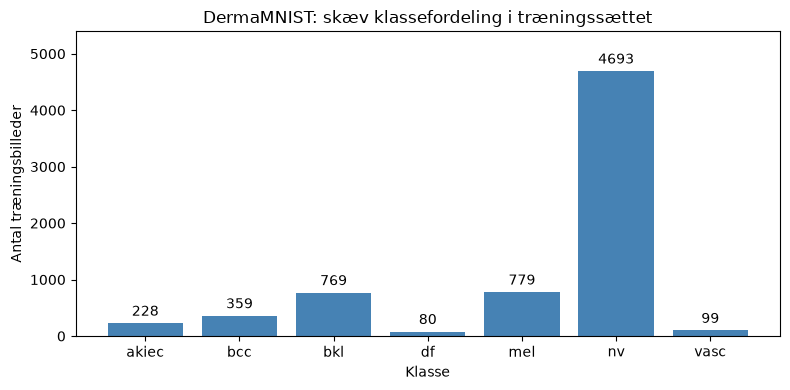

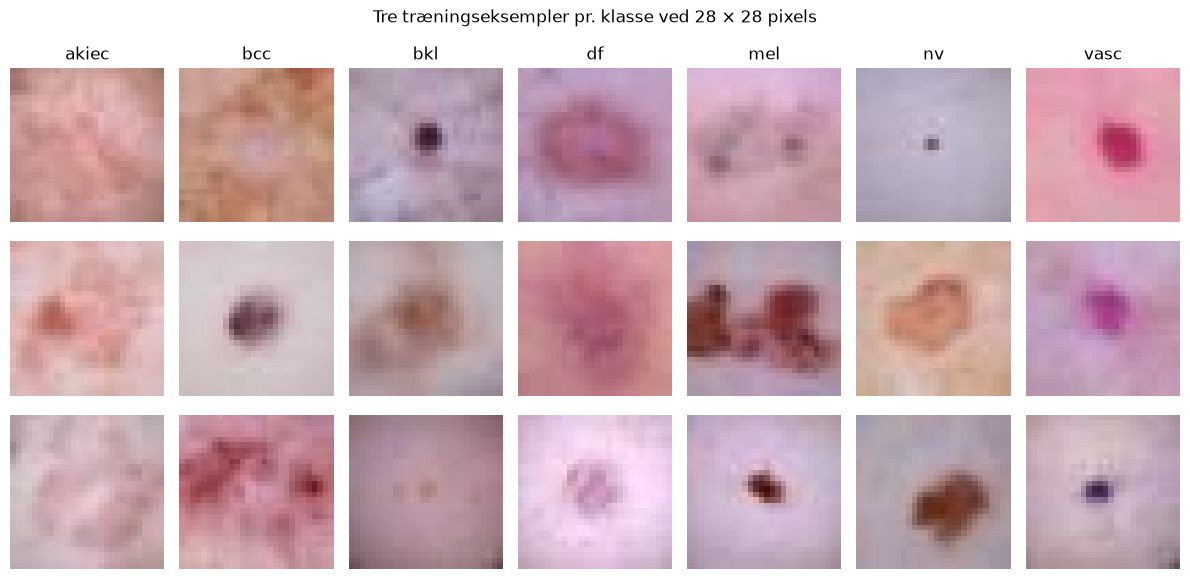

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(SHORT_NAMES, train_counts, color='steelblue')
ax.bar_label(bars, padding=3)
ax.set(xlabel='Klasse', ylabel='Antal træningsbilleder',
       title='DermaMNIST: skæv klassefordeling i træningssættet')
ax.set_ylim(0, train_counts.max() * 1.15)
fig.tight_layout()
save_figure('class_distribution.png')

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, NUM_CLASSES, figsize=(12, 6))
for class_id in range(NUM_CLASSES):
    indices = rng.choice(np.flatnonzero(y_train == class_id), size=3, replace=False)
    for row, index in enumerate(indices):
        axes[row, class_id].imshow(train_data.imgs[index], interpolation='nearest')
        axes[row, class_id].axis('off')
        if row == 0:
            axes[row, class_id].set_title(SHORT_NAMES[class_id])
fig.suptitle('Tre træningseksempler pr. klasse ved 28 × 28 pixels')
fig.tight_layout()
save_figure('sample_images.png')


Eksemplerne bruges til at undersøge variation i farve, størrelse, afgrænsning
og baggrund inden for hver klasse og lighed mellem klasser. Ved 28 × 28 pixels
går fine strukturer tabt. Billederne ovenfor er træningseksempler og er ikke
valgt efter, om modellen klassificerer dem korrekt.

## 3. Forbehandling og klassevægte

`ToTensor` skalerer RGB-værdier fra 0–255 til 0–1 og ændrer rækkefølgen fra
H × W × C til C × H × W. Derefter standardiseres hver farvekanal med
gennemsnit og standardafvigelse beregnet **udelukkende på træningsdata**.

Kun træningsbilleder spejles tilfældigt vandret og lodret, hver med p = 0,5.
Retningen er ikke labeldefinerende for disse dermatoskopiske billeder.
Farverne ændres ikke. Validerings- og testdata behandles deterministisk.
Klassevægtene er `N / (K * n_c)`, så sjældne klasser får større vægt i tabet.


In [4]:
pixels = train_data.imgs.astype(np.float32) / 255.0
mean = pixels.mean(axis=(0, 1, 2), dtype=np.float64).tolist()
std = pixels.std(axis=(0, 1, 2), dtype=np.float64).tolist()
del pixels
eval_transform = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize(mean=mean, std=std),
])
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(), transforms.Normalize(mean=mean, std=std),
])
train_data.transform = train_transform
val_data.transform = eval_transform
class_weights = torch.tensor(
    len(y_train) / (NUM_CLASSES * train_counts), dtype=torch.float32, device=DEVICE,
)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print('Train mean:', np.round(mean, 4))
print('Train std: ', np.round(std, 4))
print('Klassevægte:', class_weights.cpu().numpy().round(3))


Train mean: [0.7631 0.5381 0.5614]
Train std:  [0.1366 0.1543 0.1692]
Klassevægte: [ 4.39   2.788  1.302 12.512  1.285  0.213 10.111]


## 4. En lille CNN fra bunden

Tre 3 × 3-konvolutioner med 32, 64 og 128 filtre udtrækker lokale mønstre.
Padding = 1 bevarer billedstørrelsen gennem konvolutionerne. To max-poolings
reducerer 28 → 14 → 7. Batch normalization og ReLU følger hver konvolution.
Global average pooling erstatter et stort fuldt forbundet netværk.
Dropout = 0,3 og weight decay begrænser overfitting.

Det sidste lineære lag producerer **syv logits**. Der bruges ikke softmax
før `CrossEntropyLoss`, som allerede håndterer denne beregning numerisk stabilt.
Softmax bruges ved evaluering til ROC-AUC og til at vise modelscorer.


In [5]:
class SimpleCNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten(), nn.Dropout(dropout), nn.Linear(128, NUM_CLASSES),
        )

    def forward(self, images):
        return self.layers(images)

set_seed()
preview_model = SimpleCNN().to(DEVICE).eval()
probe = torch.zeros(1, 3, 28, 28, device=DEVICE)
architecture = []
with torch.no_grad():
    for layer in preview_model.layers:
        probe = layer(probe)
        row = {'layer': type(layer).__name__, 'output_shape': str(tuple(probe.shape)),
               'parameters': sum(p.numel() for p in layer.parameters())}
        architecture.append(row)
        print(f'{row["layer"]:20s} {row["output_shape"]:20s} {row["parameters"]:7d}')
parameter_count = sum(p.numel() for p in preview_model.parameters())
print('Antal trænérbare parametre:', parameter_count)
assert probe.shape == (1, NUM_CLASSES)


Conv2d               (1, 32, 28, 28)          896
BatchNorm2d          (1, 32, 28, 28)           64
ReLU                 (1, 32, 28, 28)            0
MaxPool2d            (1, 32, 14, 14)            0
Conv2d               (1, 64, 14, 14)        18496
BatchNorm2d          (1, 64, 14, 14)          128
ReLU                 (1, 64, 14, 14)            0
MaxPool2d            (1, 64, 7, 7)              0
Conv2d               (1, 128, 7, 7)         73856
BatchNorm2d          (1, 128, 7, 7)           256
ReLU                 (1, 128, 7, 7)             0
AdaptiveAvgPool2d    (1, 128, 1, 1)             0
Flatten              (1, 128)                   0
Dropout              (1, 128)                   0
Linear               (1, 7)                   903
Antal trænérbare parametre: 94599


## 5. Kontrol før det egentlige forsøg

Først kontrolleres initialt uvægtet tab mod ln(7) ≈ 1,946. Det er en
tommelfingerregel, ikke et præcist krav til tilfældige logits.
Derefter skal en **separat** model kunne lære 28 træningsbilleder uden
augmentation, dropout eller weight decay. Den kasseres bagefter og tæller
ikke som et modelresultat. Kontrollen bruger hverken validerings- eller testdata.


In [6]:
from PIL import Image

indices = np.concatenate([
    np.flatnonzero(y_train == c)[:4] for c in range(NUM_CLASSES)
])
small_x = torch.stack([
    eval_transform(Image.fromarray(train_data.imgs[i])) for i in indices
]).to(DEVICE)
small_y = torch.tensor(y_train[indices], dtype=torch.long, device=DEVICE)
with torch.no_grad():
    initial_loss = nn.functional.cross_entropy(preview_model(small_x), small_y).item()
print(f'Initialt uvægtet tab: {initial_loss:.4f}; ln(7): {np.log(NUM_CLASSES):.4f}')

set_seed()
sanity_model = SimpleCNN(dropout=0.0).to(DEVICE)
sanity_optimizer = torch.optim.Adam(sanity_model.parameters(), lr=3e-3)
for sanity_step in range(200):
    sanity_model.train()
    sanity_optimizer.zero_grad()
    sanity_loss = nn.functional.cross_entropy(sanity_model(small_x), small_y)
    sanity_loss.backward()
    sanity_optimizer.step()
sanity_model.eval()
with torch.no_grad():
    sanity_accuracy = (sanity_model(small_x).argmax(1) == small_y).float().mean().item()
print(f'Kontrol på 28 træningsbilleder efter 200 opdateringer: {sanity_accuracy:.1%}')
assert sanity_accuracy >= 0.95, 'Undersøg træningen før det egentlige forsøg.'
del sanity_model, sanity_optimizer, preview_model


Initialt uvægtet tab: 1.9402; ln(7): 1.9459
Kontrol på 28 træningsbilleder efter 200 opdateringer: 100.0%


## 6. Træningsfunktion og modelvalg

Samme funktion bruges til træning og evaluering. `optimizer=None` betyder
evaluering: `model.eval()` og ingen gradienter. Labels ændres fra (B, 1)
til (B,) og til heltal. Hver træningsbatch udfører zero_grad → forward →
loss → backward → step.

Det vægtede epoch-tab beregnes som summen af vægtede tab divideret med
summen af de tilhørende klassevægte [5]. Dermed aggregeres batches korrekt.
Både train- og val-kurverne bruger samme tabsdefinition.


In [7]:
criterion = nn.CrossEntropyLoss(weight=class_weights, reduction='sum')

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = 0.0
    weight_sum = 0.0
    targets, probabilities = [], []
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.reshape(-1).long().to(DEVICE)
            if training:
                optimizer.zero_grad()
            logits = model(images)
            batch_loss_sum = criterion(logits, labels)
            batch_weight = class_weights[labels].sum()
            loss = batch_loss_sum / batch_weight
            if not torch.isfinite(loss):
                raise RuntimeError('Tabet er ikke endeligt; undersøg input og learning rate.')
            if training:
                loss.backward()
                optimizer.step()
            loss_sum += batch_loss_sum.item()
            weight_sum += batch_weight.item()
            targets.append(labels.detach().cpu().numpy())
            probabilities.append(logits.detach().softmax(dim=1).cpu().numpy())
    targets = np.concatenate(targets)
    probabilities = np.concatenate(probabilities)
    predictions = probabilities.argmax(axis=1)
    metrics = {
        'loss': loss_sum / weight_sum,
        'accuracy': accuracy_score(targets, predictions),
        'macro_f1': f1_score(targets, predictions, labels=range(NUM_CLASSES),
                             average='macro', zero_division=0),
    }
    return metrics, targets, probabilities

def fit_model(learning_rate):
    # Nulstil både modelinitialisering, augmentation og batchrækkefølge pr. forsøg.
    set_seed()
    train_loader = DataLoader(
        train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(SEED),
    )
    model = SimpleCNN().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate,
                                  weight_decay=WEIGHT_DECAY)
    best_score, best_epoch, best_state = -1.0, 0, None
    history = []
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        train_metrics, _, _ = run_epoch(model, train_loader, optimizer)
        val_metrics, _, _ = run_epoch(model, val_loader)
        row = {'epoch': epoch}
        row.update({f'train_{key}': value for key, value in train_metrics.items()})
        row.update({f'val_{key}': value for key, value in val_metrics.items()})
        history.append(row)
        print(f'LR={learning_rate:g} | epoch {epoch:02d} | '
              f'train loss={train_metrics["loss"]:.3f} | '
              f'val loss={val_metrics["loss"]:.3f} | '
              f'val macro-F1={val_metrics["macro_f1"]:.3f}', flush=True)
        if val_metrics['macro_f1'] > best_score:
            best_score = val_metrics['macro_f1']
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())
        if epoch - best_epoch >= PATIENCE:
            print('Early stopping: ingen forbedring i val macro-F1 i 8 epochs.')
            break
    model.load_state_dict(best_state)
    return model, history, best_epoch, time.perf_counter() - started


Vi undersøger kun learning rates **0,001 og 0,0003**, med samme arkitektur,
seed, augmentation, klassevægte og træningsbudget. AdamW bruger konstant
learning rate og weight decay = 0,0001. Batch size = 128; højst 30 epochs.
Early stopping stopper efter 8 epochs uden forbedring af validerings-macro-F1.
Den bedste epoch gendannes for hver kandidat, og vinderen vælges alene ud fra
validerings-macro-F1. Ved præcis lighed beholdes det først afprøvede resultat.
En scheduler og en større søgning er fravalgt for at holde forsøget enkelt.


In [8]:
tuning_results = []
histories = {}
best_model = None
best_val_f1 = -1.0
for learning_rate in LEARNING_RATES:
    candidate, history, best_epoch, seconds = fit_model(learning_rate)
    best_row = history[best_epoch - 1]
    histories[str(learning_rate)] = history
    tuning_results.append({
        'learning_rate': learning_rate, 'best_epoch': best_epoch,
        'epochs_run': len(history), 'val_macro_f1': best_row['val_macro_f1'],
        'val_accuracy': best_row['val_accuracy'], 'val_loss': best_row['val_loss'],
        'seconds': seconds,
    })
    if best_row['val_macro_f1'] > best_val_f1:
        best_model = candidate
        best_val_f1 = best_row['val_macro_f1']
        best_lr = learning_rate
        selected_epoch = best_epoch
print('\nModelvalg udelukkende på valideringsdata:')
for row in tuning_results:
    print(row)
print(f'Valgt learning rate: {best_lr:g}; epoch: {selected_epoch}; '
      f'val macro-F1: {best_val_f1:.4f}')
write_csv('tuning_results.csv', tuning_results)
for learning_rate, history in histories.items():
    write_csv(f'history_lr_{learning_rate}.csv', history)


LR=0.001 | epoch 01 | train loss=1.670 | val loss=1.658 | val macro-F1=0.240
LR=0.001 | epoch 02 | train loss=1.506 | val loss=1.463 | val macro-F1=0.333
LR=0.001 | epoch 03 | train loss=1.439 | val loss=1.311 | val macro-F1=0.354
LR=0.001 | epoch 04 | train loss=1.376 | val loss=1.299 | val macro-F1=0.367
LR=0.001 | epoch 05 | train loss=1.312 | val loss=1.342 | val macro-F1=0.339
LR=0.001 | epoch 06 | train loss=1.299 | val loss=1.250 | val macro-F1=0.377
LR=0.001 | epoch 07 | train loss=1.232 | val loss=1.197 | val macro-F1=0.364
LR=0.001 | epoch 08 | train loss=1.239 | val loss=1.181 | val macro-F1=0.393
LR=0.001 | epoch 09 | train loss=1.219 | val loss=1.224 | val macro-F1=0.362
LR=0.001 | epoch 10 | train loss=1.207 | val loss=1.254 | val macro-F1=0.352
LR=0.001 | epoch 11 | train loss=1.197 | val loss=1.295 | val macro-F1=0.328
LR=0.001 | epoch 12 | train loss=1.188 | val loss=1.205 | val macro-F1=0.407
LR=0.001 | epoch 13 | train loss=1.157 | val loss=1.151 | val macro-F1=0.405

## 7. Træningskurver

Den lodrette stiplede linje markerer den valgte epoch. Valideringskurverne
viser også begge learning rates. Træningsmål måles under opdateringerne med
dropout og augmentation; valideringsmål måles efter hver epoch uden disse.
Derfor er de to kurver ikke en helt ens måling af trænings- og valideringsfejl.


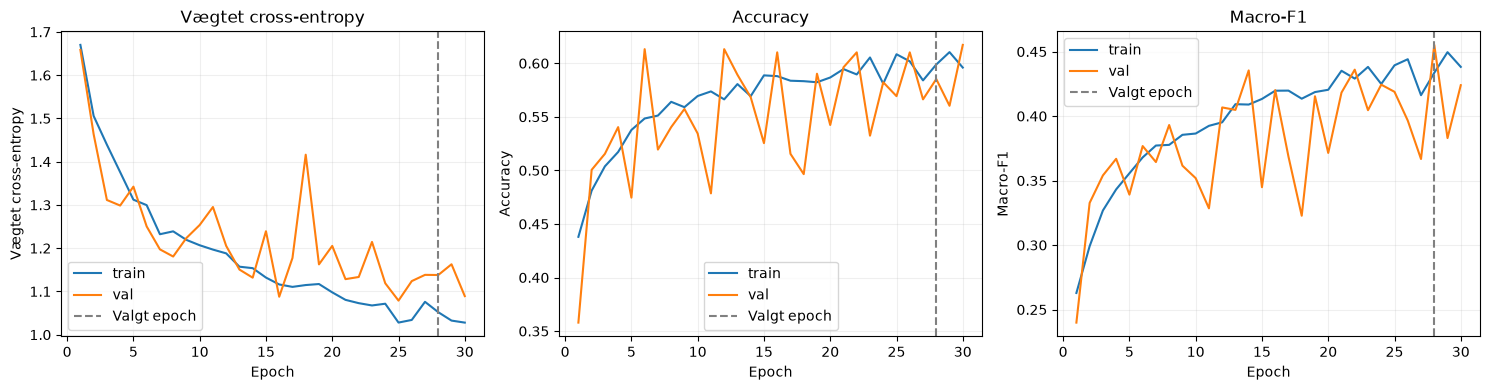

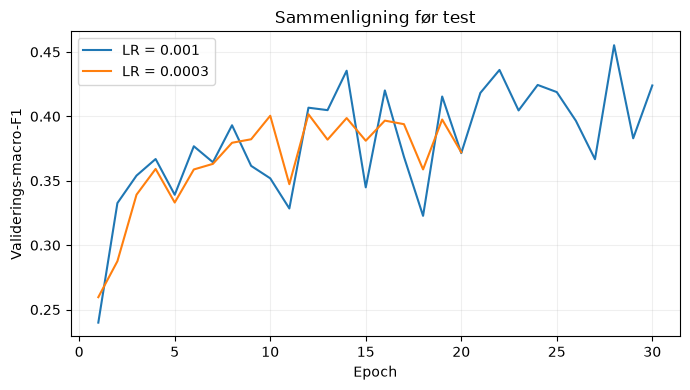

In [9]:
selected_history = histories[str(best_lr)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(axes, ['loss', 'accuracy', 'macro_f1'],
                              ['Vægtet cross-entropy', 'Accuracy', 'Macro-F1']):
    for split in ['train', 'val']:
        ax.plot([r['epoch'] for r in selected_history],
                [r[f'{split}_{metric}'] for r in selected_history], label=split)
    ax.axvline(selected_epoch, color='gray', linestyle='--', label='Valgt epoch')
    ax.set(xlabel='Epoch', ylabel=title, title=title)
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
save_figure('training_curves.png')

fig, ax = plt.subplots(figsize=(7, 4))
for learning_rate, history in histories.items():
    ax.plot([r['epoch'] for r in history], [r['val_macro_f1'] for r in history],
            label=f'LR = {learning_rate}')
ax.set(xlabel='Epoch', ylabel='Validerings-macro-F1', title='Sammenligning før test')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
save_figure('validation_comparison.png')


## 8. Endelig evaluering på testsættet

Modelvalget er afsluttet. Først nu indlæses testsættet og den valgte CNN
køres **én gang** over alle 2.005 testbilleder. Alle efterfølgende mål,
figurer og fejleksempler beregnes fra de gemte forudsigelser. Der trænes
ikke videre efter at have set testen.

Baseline forudsiger altid den hyppigste klasse fra **træningssættet**.
Accuracy, balanced accuracy, macro-F1 og macro ROC-AUC (one-vs-rest)
suppleres med precision, recall, specificitet og F1 pr. klasse.
AUC bruger softmax-scorer, mens de øvrige klassifikationsmål bruger argmax.


In [10]:
test_data = DermaMNIST(root=str(DATA_DIR), split='test', size=28,
                      transform=eval_transform, download=False)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_metrics, y_test, test_probabilities = run_epoch(best_model, test_loader)
y_pred = test_probabilities.argmax(axis=1)
assert len(y_test) == 2005
assert test_probabilities.shape == (2005, NUM_CLASSES)
assert np.allclose(test_probabilities.sum(axis=1), 1.0, atol=1e-5)
test_metrics.update({
    'balanced_accuracy': balanced_accuracy_score(y_test, y_pred),
    'macro_auc_ovr': roc_auc_score(y_test, test_probabilities,
                                  average='macro', multi_class='ovr'),
    'cohen_kappa': cohen_kappa_score(y_test, y_pred),
})
baseline_pred = np.full(len(y_test), majority_class)
baseline_metrics = {
    'accuracy': accuracy_score(y_test, baseline_pred),
    'balanced_accuracy': balanced_accuracy_score(y_test, baseline_pred),
    'macro_f1': f1_score(y_test, baseline_pred, labels=range(NUM_CLASSES),
                         average='macro', zero_division=0),
}
print('CNN testresultater:', {k: round(v, 4) for k, v in test_metrics.items()})
print('Majoritetsbaseline:', {k: round(v, 4) for k, v in baseline_metrics.items()})
print(classification_report(y_test, y_pred, labels=range(NUM_CLASSES),
                            target_names=CLASS_NAMES, digits=4, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES))
report = classification_report(y_test, y_pred, labels=range(NUM_CLASSES),
                                target_names=SHORT_NAMES, output_dict=True, zero_division=0)
per_class = []
for c, name in enumerate(SHORT_NAMES):
    tp = cm[c, c]
    fp = cm[:, c].sum() - tp
    fn = cm[c, :].sum() - tp
    tn = cm.sum() - tp - fp - fn
    per_class.append({
        'class': name, 'label': CLASS_NAMES[c],
        'precision': report[name]['precision'], 'recall': report[name]['recall'],
        'specificity': float(tn / (tn + fp)), 'f1': report[name]['f1-score'],
        'auc_ovr': roc_auc_score((y_test == c).astype(int), test_probabilities[:, c]),
        'support': int(cm[c].sum()),
    })
val_counts = np.bincount(val_data.labels.reshape(-1), minlength=NUM_CLASSES)
test_counts = np.bincount(y_test, minlength=NUM_CLASSES)
distribution = [{'class': SHORT_NAMES[c], 'label': CLASS_NAMES[c],
                 'train': int(train_counts[c]), 'val': int(val_counts[c]),
                 'test': int(test_counts[c])} for c in range(NUM_CLASSES)]
print('Specificitet pr. klasse:', {r['class']: round(r['specificity'], 4) for r in per_class})
print('Endelig klassefordeling:', distribution)


CNN testresultater: {'loss': 1.0874, 'accuracy': 0.6095, 'macro_f1': 0.4808, 'balanced_accuracy': 0.5972, 'macro_auc_ovr': 0.9132, 'cohen_kappa': 0.4157}
Majoritetsbaseline: {'accuracy': 0.6688, 'balanced_accuracy': 0.1429, 'macro_f1': 0.1145}
                                                 precision    recall  f1-score   support

actinic keratoses and intraepithelial carcinoma     0.3022    0.6364    0.4098        66
                           basal cell carcinoma     0.5541    0.3981    0.4633       103
                  benign keratosis-like lesions     0.4051    0.5818    0.4776       220
                                 dermatofibroma     0.0965    0.4783    0.1606        23
                                       melanoma     0.3186    0.6771    0.4333       223
                               melanocytic nevi     0.9741    0.6160    0.7547      1341
                               vascular lesions     0.5750    0.7931    0.6667        29

                                       acc

## 9. Confusion matrix og ROC-kurver

Rækkerne i confusion matrix er de sande klasser; kolonnerne er forudsigelserne.
Den normaliserede udgave viser andelen af hver sand klasse. Dens diagonal er
recall pr. klasse. ROC behandler én klasse ad gangen som positiv og de seks
andre som negative. Macro-AUC er gennemsnittet af de syv AUC-værdier.


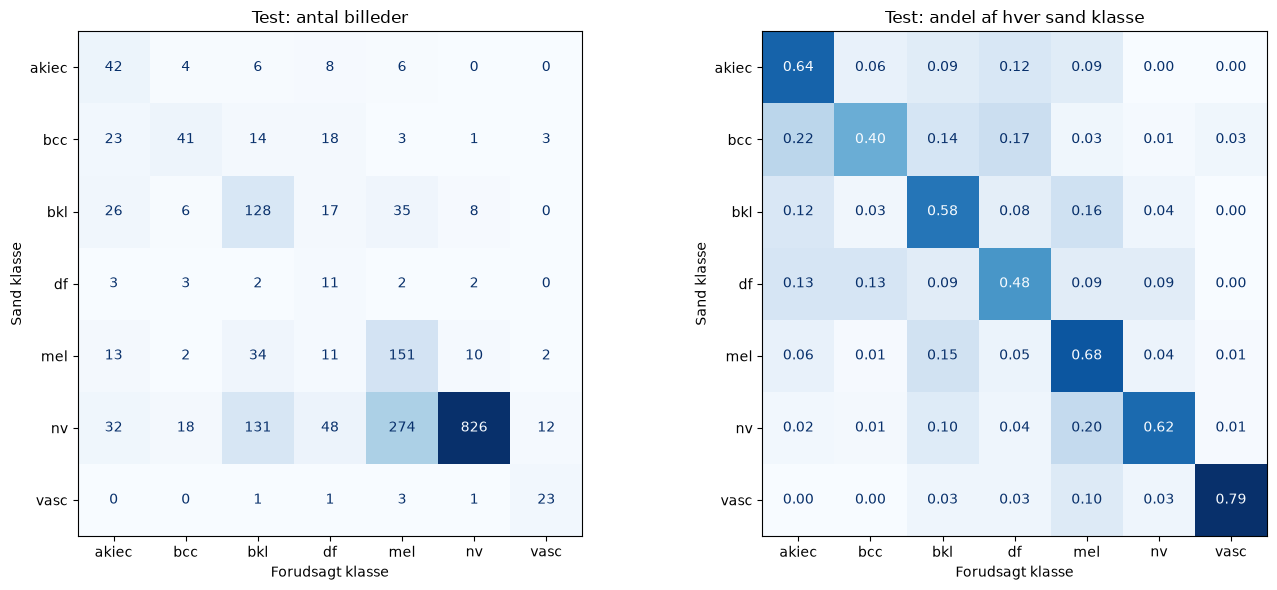

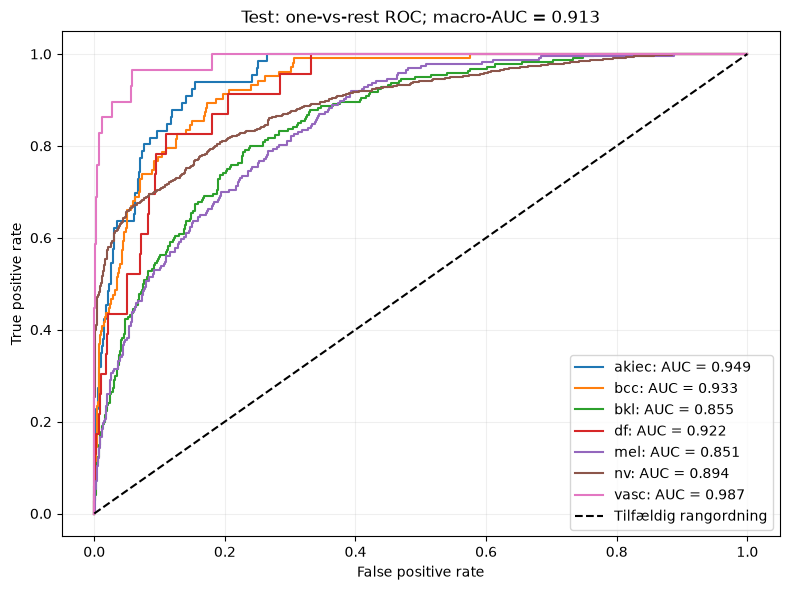

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ConfusionMatrixDisplay(cm, display_labels=SHORT_NAMES).plot(
    ax=axes[0], cmap='Blues', colorbar=False, values_format='d')
normalized_cm = cm / cm.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(normalized_cm, display_labels=SHORT_NAMES).plot(
    ax=axes[1], cmap='Blues', colorbar=False, values_format='.2f')
for ax, title in zip(axes, ['Test: antal billeder', 'Test: andel af hver sand klasse']):
    ax.set(title=title, xlabel='Forudsagt klasse', ylabel='Sand klasse')
fig.tight_layout()
save_figure('confusion_matrices.png')

fig, ax = plt.subplots(figsize=(8, 6))
for c, name in enumerate(SHORT_NAMES):
    fpr, tpr, _ = roc_curve(y_test == c, test_probabilities[:, c])
    ax.plot(fpr, tpr, label=f'{name}: AUC = {per_class[c]["auc_ovr"]:.3f}')
ax.plot([0, 1], [0, 1], 'k--', label='Tilfældig rangordning')
ax.set(xlabel='False positive rate', ylabel='True positive rate',
       title=f'Test: one-vs-rest ROC; macro-AUC = {test_metrics["macro_auc_ovr"]:.3f}')
ax.legend(loc='lower right')
ax.grid(alpha=0.2)
fig.tight_layout()
save_figure('roc_curves.png')


## 10. Kvalitativ fejlanalyse

Vi viser op til to fejl pr. sand klasse i fast datasætrækkefølge. Det giver
en mere systematisk udvælgelse end kun at vise de mest dramatiske fejl.
Tallet p er modellens softmax-score for den valgte klasse; det er ikke en
kalibreret klinisk sikkerhed. Billederne ændrer ikke modelvalget.


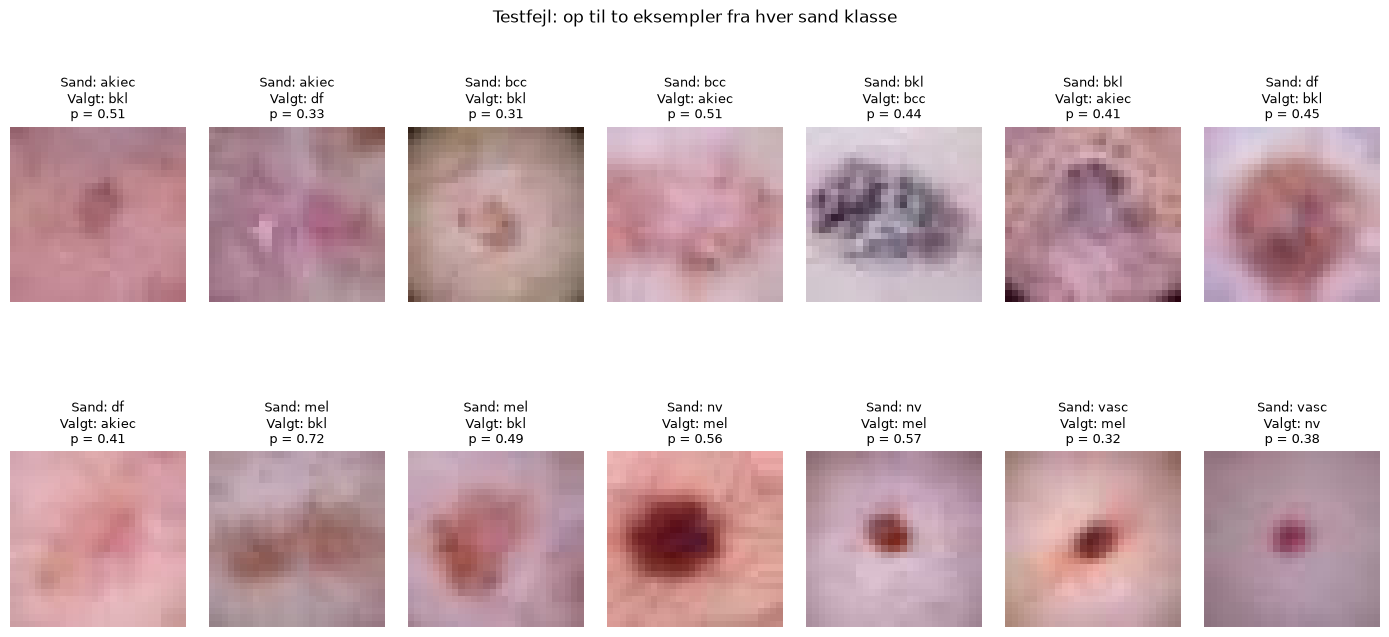

Hyppigste forvekslinger (antal):
nv -> mel: 274
nv -> bkl: 131
nv -> df: 48
bkl -> mel: 35
mel -> bkl: 34


In [12]:
error_indices = []
for c in range(NUM_CLASSES):
    error_indices.extend(np.flatnonzero((y_test == c) & (y_pred != y_test))[:2])
fig, axes = plt.subplots(2, 7, figsize=(14, 6.5))
for ax in axes.flat:
    ax.axis('off')
for ax, index in zip(axes.flat, error_indices):
    ax.imshow(test_data.imgs[index], interpolation='nearest')
    ax.set_title(f'Sand: {SHORT_NAMES[y_test[index]]}\n'
                 f'Valgt: {SHORT_NAMES[y_pred[index]]}\n'
                 f'p = {test_probabilities[index, y_pred[index]]:.2f}', fontsize=9)
fig.suptitle('Testfejl: op til to eksempler fra hver sand klasse')
fig.subplots_adjust(left=0.01, right=0.99, bottom=0.03, top=0.80,
                    hspace=0.85, wspace=0.12)
save_figure('misclassified_examples.png')

wrong_pairs = cm.copy()
np.fill_diagonal(wrong_pairs, 0)
print('Hyppigste forvekslinger (antal):')
for flat_index in np.argsort(wrong_pairs, axis=None)[::-1][:5]:
    actual, predicted = np.unravel_index(flat_index, wrong_pairs.shape)
    if wrong_pairs[actual, predicted] > 0:
        print(f'{SHORT_NAMES[actual]} -> {SHORT_NAMES[predicted]}: '
              f'{wrong_pairs[actual, predicted]}')


## 11. Gem model, resultater og forsøgsindstillinger

Checkpointet indeholder også normalisering, labels og modelindstillinger.
`test_predictions.csv` gemmer alle testscorer i samme rækkefølge som
MedMNISTs testsæt. CSV-filer og PNG-figurer kan bruges i rapporten.
En ny kørsel overskriver filerne i `results`; kopiér mappen først, hvis
et tidligere forsøg skal bevares. Den skrevne rapport opdateres ikke automatisk.


In [13]:
config = {
    'dataset': 'dermamnist', 'size': 28, 'seed': SEED,
    'batch_size': BATCH_SIZE, 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE,
    'learning_rates': LEARNING_RATES, 'selected_learning_rate': best_lr,
    'selected_epoch': selected_epoch, 'weight_decay': WEIGHT_DECAY,
    'dropout': 0.3, 'selection_metric': 'validation macro-F1',
    'normalization_mean': mean, 'normalization_std': std,
    'class_weights': class_weights.cpu().tolist(), 'class_names': CLASS_NAMES,
    'device': str(DEVICE), 'python': platform.python_version(),
    'platform': platform.platform(), 'versions': VERSIONS,
    'parameters': parameter_count,
    'sanity_accuracy': sanity_accuracy, 'initial_loss': initial_loss,
}
summary = {'config': config, 'tuning': tuning_results, 'test': test_metrics,
           'baseline': baseline_metrics, 'per_class': per_class,
           'class_distribution': distribution, 'confusion_matrix': cm.tolist()}
with (RESULTS_DIR / 'metrics.json').open('w', encoding='utf-8') as file:
    json.dump(summary, file, ensure_ascii=False, indent=2)
torch.save({'model_state_dict': {k: v.cpu() for k, v in best_model.state_dict().items()},
            'config': config}, RESULTS_DIR / 'best_model.pt')
write_csv('architecture.csv', architecture)
write_csv('class_distribution.csv', distribution)
write_csv('per_class_metrics.csv', per_class)
prediction_rows = []
for i in range(len(y_test)):
    row = {'test_index': i, 'true_label': int(y_test[i]), 'predicted_label': int(y_pred[i])}
    row.update({f'prob_{name}': float(test_probabilities[i, c])
                for c, name in enumerate(SHORT_NAMES)})
    prediction_rows.append(row)
write_csv('test_predictions.csv', prediction_rows)
print('Gemt: checkpoint, metrics, CSV-tabeller og figurer i', RESULTS_DIR)


Gemt: checkpoint, metrics, CSV-tabeller og figurer i /Users/frederikthygesen/Desktop/5 Semester/Deep Learning/Assignment 1/Deeplearning/Assignment_2/results


## 12. Diskussion og konklusion

Den gemte kørsel valgte learning rate 0,001 og epoch 28 på valideringsdata.

| Testmål | CNN | Majoritetsbaseline |
| --- | ---: | ---: |
| Accuracy | 0,6095 | 0,6688 |
| Balanced accuracy | 0,5972 | 0,1429 |
| Macro-F1 | 0,4808 | 0,1145 |
| Macro-AUC OVR | 0,9132 | Ikke beregnet |

CNN’en har lavere accuracy og bedre genkendelse på tværs af klasserne.
Nv→mel er den hyppigste forveksling med 274 billeder. Mel har recall
0,6771 og precision 0,3186, mens df har F1 0,1606. Resultaterne viser
derfor betydelige begrænsninger, selv om macro-AUC er relativt høj.

Tabellen beskriver den medfølgende kørsel; den opdateres ikke automatisk
ved genkørsel. Brug de nye resultater i afsnit 8 ved et nyt forsøg.
`Rapport.md` indeholder analysen af den gemte kørsel. Modellen sammenlignes
med majoritetsbaselinen på accuracy, balanced accuracy og macro-F1.
Valideringsforsøget viser kun, hvilken af to learning rates der virker bedst
i denne kørsel; det beviser ikke en generel fordel eller en optimal løsning.

Som litteraturreference rapporterer MedMNIST v2 for ResNet-18 ved 28 × 28
en test-accuracy på 0,735 og AUC på 0,917 [1, 4]. Det er en offentliggjort
baseline, ikke et nyt forsøg her eller en påstand om aktuel state of the art.
Arkitektur, træningsbudget og udvælgelseskriterium er forskellige.

Vigtige begrænsninger er lav opløsning, få eksempler i små klasser, én seed,
et snævert hyperparameterforsøg og kendt læsionsoverlap i standardsplittene [3].
Et bedre opfølgende forsøg kunne anvende læsionsadskilte data, flere seeds,
højere oprindelig billedopløsning eller en lille prætrænet model.

## Referencer

[1] Yang et al. (2023). *MedMNIST v2—A large-scale lightweight benchmark
for 2D and 3D biomedical image classification*. Scientific Data 10, 41.
https://doi.org/10.1038/s41597-022-01721-8

[2] Tschandl, Rosendahl & Kittler (2018). *The HAM10000 dataset, a large collection
of multi-source dermatoscopic images of common pigmented skin lesions*.
Scientific Data 5, 180161. https://doi.org/10.1038/sdata.2018.161

[3] Abhishek, Jain & Hamarneh (2025). *Investigating the Quality of DermaMNIST
and Fitzpatrick17k Dermatological Image Datasets*. Scientific Data 12, 196.
https://doi.org/10.1038/s41597-025-04382-5

[4] MedMNISTs officielle benchmark: https://medmnist.com/

[5] PyTorch: vægtet cross-entropy og reduktion.
https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html

Data: DermaMNIST, MedMNIST/HAM10000, CC BY-NC 4.0.
Opgavens struktur følger den udleverede Assignment 2 description;
masterguiden bruges som metodebaggrund. Dens eksempler på avancerede
modeller er ikke behandlet som krav om at implementere dem alle.
